# Model: regression and k-means

**ZHAW Data Analytics HS2026 · Group project «Electricity prices of Swiss municipalities» · Part Subraj**

This notebook covers mandatory requirement 5 (model with a comparison over time), mandatory requirement 6 (model quality), mandatory requirement 7 (interpretation) and bonus point 5 (k-means in addition to the model). It builds on `03_analyse_subraj.ipynb`: the decisions made there (section 9) are implemented here.

**Research question:** Which characteristics of a municipality explain the level of its household electricity price, and did these relationships change with the price increase of 2023?

| Section | Content |
|---|---|
| 0 | Load data and prepare characteristics |
| 1 | Model choice: variables and multicollinearity |
| 2 | Estimation method: OLS with standard errors clustered by grid operator |
| 3 | Model A: the same characteristics for three years and two increases |
| 4 | Model B: canton added |
| 5 | Model C: at the level of the grid operators |
| 6 | Model quality out of sample |
| 7 | Residuals |
| 8 | k-means: municipality types |
| 9 | Conclusion |

## 0 · Load data

As in notebook 03: analysis table via SQL from the SQLite database; canton, language region, municipality type and grid operator from Lenny's joined table.

New is `anz_gemeinden_betreiber`: the number of municipalities the grid operator supplies in category H4 in 2027 (integration documentation, section 7b). It serves as the measure of the **size of the grid operator**.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GroupKFold, KFold
from sklearn.preprocessing import StandardScaler


def finde_wurzel(start: Path) -> Path:
    # Climbs upwards until daten/ and scripts/ sit side by side
    for ordner in [start, *start.parents]:
        if (ordner / "daten").is_dir() and (ordner / "scripts").is_dir():
            return ordner
    raise RuntimeError(f"Repository root not found starting from {start}")


WURZEL = finde_wurzel(Path.cwd().resolve())
JAHRE = [2021, 2024, 2027]
FARBE = {"total_2021": "#2a78d6", "total_2024": "#eb6834", "total_2027": "#1baf7a",
         "anstieg_21_24": "#e87ba4", "anstieg_21_27": "#6250d6"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#898781",
    "ytick.color": "#898781", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

con = sqlite3.connect(WURZEL / "sql" / "strompreise.db")
df = pd.read_sql("SELECT * FROM v_analyse", con)
con.close()

zusatz = pd.read_csv(WURZEL / "daten" / "verbunden" / "strompreise_gemeinden.csv",
                     usecols=["gemeinde_nr", "netzbetreiber_id", "netzbetreiber", "kanton",
                              "sprachregion", "gemeindetyp_9", "anz_gemeinden_betreiber"])
df = df.merge(zusatz, on="gemeinde_nr", how="left", validate="one_to_one")
assert len(df) == 2087 and df["kanton"].notna().all(), "Expected 2087 municipalities, each with a canton"

# Target variables
df["anstieg_21_24"] = df["total_2024"] - df["total_2021"]
df["anstieg_21_27"] = df["total_2027"] - df["total_2021"]

# Characteristics, right-skewed ones log-transformed (reason: notebook 03, section 5.1)
df["log_dichte"] = np.log10(df["dichte"])
df["log_flaeche"] = np.log10(df["flaeche_total"])
df["log_betreibergroesse"] = np.log10(df["anz_gemeinden_betreiber"])
df["beschaeftigte_pro_einw"] = df["beschaeftigte"] / df["einwohner"]

ZIELE = {"total_2021": "Price 2021", "total_2024": "Price 2024", "total_2027": "Price 2027",
         "anstieg_21_24": "Increase 21–24", "anstieg_21_27": "Increase 21–27"}
print(f"{len(df)} municipalities, {df['netzbetreiber_id'].nunique()} grid operators")

2087 municipalities, 485 grid operators


## 1 · Model choice

### 1.1 Which characteristics enter the model

| Characteristic | in the model | Reason |
|---|---|---|
| Density (log) | yes | urban or rural; in notebook 03 the strongest relationship with the increase |
| Area (log) | yes | a large area means many kilometres of lines per customer |
| Share aged 65+ | yes | robustly related to the increase in notebook 03 |
| Size of the grid operator (log) | yes | large operators buy electricity in larger quantities and over longer periods |
| Language region | yes, as dummies | comparing the regions is part of the question; the reference is German-speaking Switzerland |
| Population | no | equals density times area; with both, the model would be exactly collinear |
| Jobs | only in one variant | missing for 88 municipalities, correlated with population at 0.94; as share per inhabitant in section 3.4 |
| Canton | in model B | explains a lot, but hides which property lies behind it |

### 1.2 Multicollinearity

The variance inflation factor (VIF) measures how well a characteristic can be predicted from the others. Values below 5 are considered unproblematic.

In [2]:
MERKMALE = ["log_dichte", "log_flaeche", "anteil_65plus", "log_betreibergroesse"]
# Display names; the keys Französisch, Italienisch, Rätoromanisch are data values of sprachregion
NAME = {"log_dichte": "Density (log)", "log_flaeche": "Area (log)", "anteil_65plus": "Share 65+",
        "log_betreibergroesse": "Operator size (log)", "beschaeftigte_pro_einw": "Jobs per inhabitant",
        "Französisch": "French", "Italienisch": "Italian", "Rätoromanisch": "Romansh"}


def vif(daten: pd.DataFrame) -> pd.Series:
    werte = {}
    for spalte in daten:
        andere = daten.drop(columns=spalte)
        r2 = LinearRegression().fit(andere, daten[spalte]).score(andere, daten[spalte])
        werte[NAME.get(spalte, spalte)] = 1 / (1 - r2)
    return pd.Series(werte, name="VIF")


print(df[MERKMALE].corr().round(2).rename(index=NAME, columns=NAME), "\n")
vif(df[MERKMALE]).round(2)

                     Density (log)  Area (log)  Share 65+  Operator size (log)
Density (log)                 1.00       -0.53      -0.30                -0.04
Area (log)                   -0.53        1.00       0.24                -0.22
Share 65+                    -0.30        0.24       1.00                -0.06
Operator size (log)          -0.04       -0.22      -0.06                 1.00 



Density (log)          1.52
Area (log)             1.53
Share 65+              1.11
Operator size (log)    1.09
Name: VIF, dtype: float64

All VIFs are far below 5. The strongest correlation is between density and area (−0.53): municipalities with a large area are mostly sparsely populated. This is unproblematic.

### 1.3 Standardisation

The characteristics are standardised (mean 0, standard deviation 1). This makes the coefficients directly comparable: each coefficient says by how many centimes per kWh the price differs on average when the characteristic is one standard deviation higher and the others stay the same. The language regions remain dummies (0 or 1); their coefficients are differences from German-speaking Switzerland in centimes.

In [3]:
def standardisiert(daten: pd.DataFrame, spalten: list) -> pd.DataFrame:
    return (daten[spalten] - daten[spalten].mean()) / daten[spalten].std()


def regionen_dummies(sprachregion: pd.Series) -> pd.DataFrame:
    return (pd.get_dummies(sprachregion)
              .reindex(columns=["Französisch", "Italienisch", "Rätoromanisch"], fill_value=False)
              .astype(float))


X_A = pd.concat([standardisiert(df, MERKMALE), regionen_dummies(df["sprachregion"])], axis=1)
print("One standard deviation corresponds to:")
for m, s in df[MERKMALE].std().items():
    faktor = f" (factor {10 ** s:.1f} on the original scale)" if m.startswith("log_") else " percentage points"
    print(f"  {NAME[m]:<24}{s:.2f}{faktor}")

One standard deviation corresponds to:
  Density (log)           0.62 (factor 4.1 on the original scale)
  Area (log)              0.47 (factor 3.0 on the original scale)
  Share 65+               4.38 percentage points
  Operator size (log)     0.92 (factor 8.2 on the original scale)


## 2 · Estimation method

A linear regression is estimated by ordinary least squares (OLS). The coefficients are the same as with `sklearn.LinearRegression` or `statsmodels.OLS`.

The **standard errors** are different. The municipalities of one grid operator have the same price, so their errors are not independent (notebook 03, section 7). Ordinary standard errors would then be too small and the p-values too optimistic. The standard errors are therefore **clustered by grid operator** (cluster-robust covariance after Liang and Zeger, with the usual small-sample correction):

$$\hat V = (X'X)^{-1} \Big(\sum_{g} X_g' \hat e_g \hat e_g' X_g\Big) (X'X)^{-1} \cdot \frac{G}{G-1} \cdot \frac{N-1}{N-K}$$

Here $g$ is a grid operator, $G$ their number (485), $N$ the number of municipalities and $K$ the number of coefficients. The p-values come from a t-distribution with $G-1$ degrees of freedom. This corresponds to `statsmodels.OLS(...).fit(cov_type="cluster", ...)`.

In [4]:
def ols_geclustert(y: pd.Series, X: pd.DataFrame, cluster: pd.Series) -> dict:
    """OLS with a constant and standard errors clustered by `cluster`."""
    Xm = np.column_stack([np.ones(len(X)), X.to_numpy(float)])
    yv = y.to_numpy(float)
    g = cluster.to_numpy()
    n, k = Xm.shape
    beta, *_ = np.linalg.lstsq(Xm, yv, rcond=None)
    resid = yv - Xm @ beta
    brot = np.linalg.inv(Xm.T @ Xm)
    gruppen = pd.Series(np.arange(n)).groupby(g).indices.values()
    fleisch = sum(np.outer(Xm[i].T @ resid[i], Xm[i].T @ resid[i]) for i in gruppen)
    G = len(np.unique(g))
    V = brot @ fleisch @ brot * G / (G - 1) * (n - 1) / (n - k)
    se = np.sqrt(np.diag(V))
    t = beta / se
    krit = stats.t.ppf(0.975, G - 1)
    r2 = 1 - (resid @ resid) / ((yv - yv.mean()) @ (yv - yv.mean()))
    tabelle = pd.DataFrame({"Coefficient": beta, "Std. error": se, "t": t,
                            "p": 2 * stats.t.sf(np.abs(t), G - 1),
                            "95% CI lower": beta - krit * se, "95% CI upper": beta + krit * se},
                           index=["Constant"] + [NAME.get(c, c) for c in X.columns])
    return {"tabelle": tabelle, "beta": beta, "V": V, "G": G, "n": n, "k": k, "resid": resid,
            "vorhersage": Xm @ beta, "R2": r2, "R2_adj": 1 - (1 - r2) * (n - 1) / (n - k),
            "RMSE": np.sqrt(resid @ resid / n)}


def wald_test(modell: dict, positionen: list) -> tuple:
    """Joint cluster-robust test of whether the coefficients at `positionen` are all zero."""
    R = np.zeros((len(positionen), modell["k"]))
    for zeile, pos in enumerate(positionen):
        R[zeile, pos] = 1
    rb = R @ modell["beta"]
    F = rb @ np.linalg.inv(R @ modell["V"] @ R.T) @ rb / len(positionen)
    return F, stats.f.sf(F, len(positionen), modell["G"] - 1)


# Check: coefficients match scikit-learn
probe = ols_geclustert(df["total_2021"], X_A, df["netzbetreiber_id"])
sk = LinearRegression().fit(X_A, df["total_2021"])
assert np.allclose(probe["beta"], np.r_[sk.intercept_, sk.coef_]), "Coefficients differ from scikit-learn"
print("Coefficients identical to scikit-learn")

Coefficients identical to scikit-learn


In [5]:
# Cross-check with statsmodels, if installed (not one of the required packages)
try:
    import statsmodels.api as sm
    sm_fit = sm.OLS(df["total_2021"], sm.add_constant(X_A)).fit(
        cov_type="cluster", cov_kwds={"groups": df["netzbetreiber_id"]})
    assert np.allclose(sm_fit.bse.to_numpy(), probe["tabelle"]["Std. error"].to_numpy()), \
        "Standard errors differ from statsmodels"
    print("Standard errors identical to statsmodels (cov_type='cluster')")
except ImportError:
    print("statsmodels not installed, cross-check skipped")

statsmodels not installed, cross-check skipped


## 3 · Model A: the same characteristics over time

The same model is estimated for five target variables: the price in 2021, 2024 and 2027, and the increase from 2021 to 2024 and from 2021 to 2027.

The increase models are the formal test for the second part of the research question. Because the characteristics are the same in all years, the coefficient in the model «Increase 21–24» is exactly the difference between the coefficients for 2024 and 2021. Its p-value therefore tests whether the relationship changed between 2021 and 2024.

In [6]:
modelle_A = {ziel: ols_geclustert(df[ziel], X_A, df["netzbetreiber_id"]) for ziel in ZIELE}

# Check of the difference argument
assert np.allclose(modelle_A["anstieg_21_24"]["beta"],
                   modelle_A["total_2024"]["beta"] - modelle_A["total_2021"]["beta"]), \
    "Increase coefficients are not the difference of the year coefficients"

guete_A = pd.DataFrame({name: {"n": m["n"], "R²": m["R2"], "R² adj.": m["R2_adj"], "RMSE (cts.)": m["RMSE"],
                               "Std. of target": df[ziel].std(ddof=0)}
                        for (ziel, name), m in zip(ZIELE.items(), modelle_A.values())}).T
guete_A.round(3)

,n,R²,R² adj.,RMSE (cts.),Std. of target
Price 2021,2087.0,0.218,0.215,2.645,2.990
Price 2024,2087.0,0.068,0.065,3.584,3.713
Price 2027,2087.0,0.069,0.065,2.941,3.047
Increase 21–24,2087.0,0.214,0.212,3.893,4.391
Increase 21–27,2087.0,0.290,0.288,3.250,3.857


In [7]:
koeff_A = pd.concat({name: m["tabelle"][["Coefficient", "Std. error", "p"]]
                     for name, m in zip(ZIELE.values(), modelle_A.values())}, axis=1)
koeff_A.round(3)

Price 2021                    Price 2024                    Price 2027                   Increase 21–24                   Increase 21–27  \
                    Coefficient Std. error      p Coefficient Std. error      p Coefficient Std. error      p    Coefficient Std. error      p    Coefficient   
Constant                 20.725      0.849  0.000      31.674      0.310  0.000      26.999      0.447  0.000         10.948      0.962  0.000          6.274   
Density (log)            -0.081      0.254  0.749       0.624      0.241  0.010       0.044      0.229  0.848          0.705      0.285  0.014          0.125   
Area (log)                0.089      0.162  0.582      -0.160      0.172  0.354      -0.279      0.154  0.070         -0.249      0.224  0.267         -0.368   
Share 65+                 0.641      0.230  0.005      -0.107      0.182  0.556      -0.030      0.171  0.859         -0.748      0.316  0.018         -0.671   
Operator size (log)       1.191      0.691  0.085      -0.430      0.204  0.036      -0.820      0.266  0.002         -1.620      0.778  0.038         -2.011   
French                    0.303      1.040  0.771       1.002      0.674  0.138       0.955      0.776  0.219          0.699      1.248  0.576          0.652   
Italian                   0.823      1.058  0.437       0.908      1.267  0.474      -0.383      0.982  0.697          0.086      1.239  0.945         -1.206   
Romansh                   0.783      1.300  0.547      -2.613      1.248  0.037       0.003      1.857  0.999         -3.396      0.910  0.000         -0.780   

                                       
                    Std. error      p  
Constant                 0.893  0.000  
Density (log)            0.233  0.593  
Area (log)               0.181  0.043  
Share 65+                0.286  0.019  
Operator size (log)      0.721  0.005  
French                   1.177  0.580  
Italian                  1.062  0.257  
Romansh                  1.228  0.525

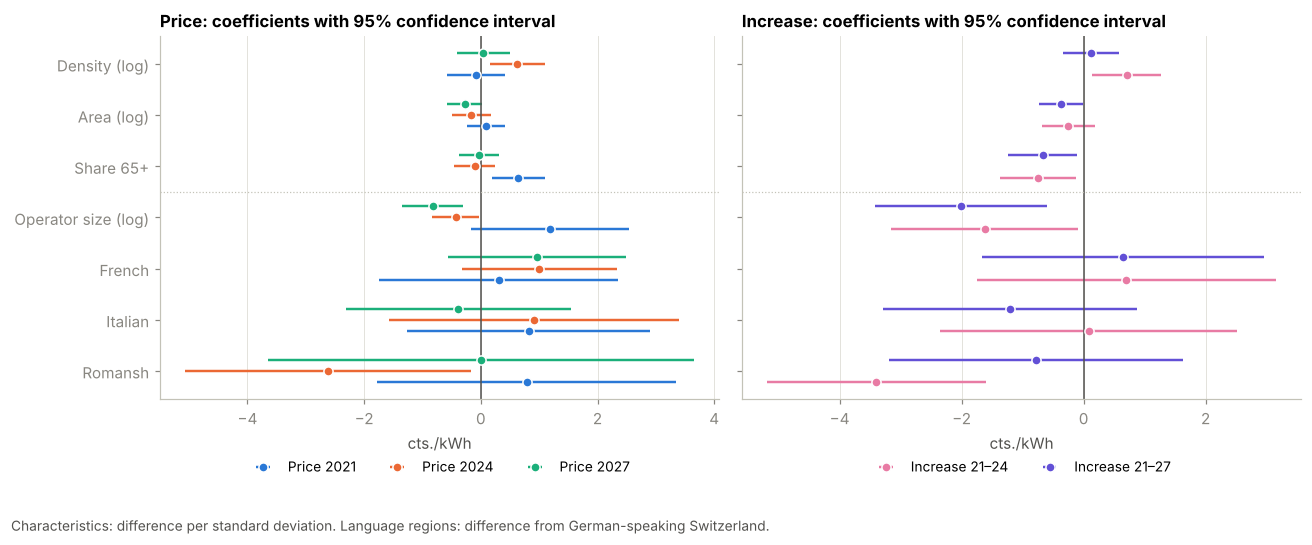

In [8]:
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
zeilen = [NAME[m] for m in MERKMALE] + [NAME[r] for r in ["Französisch", "Italienisch", "Rätoromanisch"]]
y = np.arange(len(zeilen))[::-1]
for ax, gruppe, titel in [(achsen[0], ["total_2021", "total_2024", "total_2027"], "Price"),
                          (achsen[1], ["anstieg_21_24", "anstieg_21_27"], "Increase")]:
    versatz = np.linspace(-0.22, 0.22, len(gruppe))
    for v, ziel in zip(versatz, gruppe):
        t = modelle_A[ziel]["tabelle"].loc[zeilen]
        ax.errorbar(t["Coefficient"], y + v, xerr=[t["Coefficient"] - t["95% CI lower"],
                    t["95% CI upper"] - t["Coefficient"]], fmt="o", ms=6, color=FARBE[ziel],
                    ecolor=FARBE[ziel], elinewidth=1.6, capsize=0, label=ZIELE[ziel],
                    markeredgecolor="white", markeredgewidth=1)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.axhline(3.5, color="#c3c2b7", linewidth=0.8, linestyle=":")
    ax.set_title(f"{titel}: coefficients with 95% confidence interval", loc="left")
    ax.set_xlabel("cts./kWh")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9)
    ax.grid(axis="y", visible=False)
achsen[0].set_yticks(y, zeilen)
fig.text(0.01, -0.06, "Characteristics: difference per standard deviation. Language regions: difference from German-speaking Switzerland.",
         fontsize=9, color="#52514e")
fig.tight_layout()

#### Interpretation of model quality

The model explains 22 percent of the price differences in 2021, but only 7 percent in 2024 and 2027. For the increase it is 21 percent (2021 to 2024) and 29 percent (2021 to 2027). In all models the RMSE is only slightly below the standard deviation of the target variable: in 2021, for example, 2.6 compared with 3.0 cts./kWh. A typical prediction is therefore still off by 2.6 centimes. The model describes tendencies; it cannot determine the prices of individual municipalities. This fits notebook 03: the grid operator explains 94 to 97 percent of the differences, the municipal characteristics only a small part.

The constant is the predicted price of a German-speaking municipality with average characteristics, about 20.7 cts./kWh in 2021 and 31.7 cts./kWh in 2024.

#### Interpretation of the coefficients

Three relationships changed significantly between 2021 and 2024. Significant here means: in the model «Increase 21–24» the coefficient differs from zero with p < 0.05.

1. Share aged 65+. In 2021, a municipality with a share of older people 4.4 percentage points higher was on average 0.64 cts. more expensive (p = 0.005). In 2024 there is no relationship any more (−0.11, p = 0.56). The change is −0.75 cts. (p = 0.018).
2. Density. In 2021, taking the other characteristics into account, there was no relationship (−0.08, p = 0.75). In 2024, a municipality four times as dense was on average 0.62 cts. more expensive (p = 0.010). The change is +0.70 cts. (p = 0.014). The negative relationship in 2021 from notebook 03 (Spearman −0.21) therefore disappears as soon as the share aged 65+ and operator size are taken into account.
3. Size of the grid operator. Municipalities of large operators tended to be more expensive in 2021 (+1.19, p = 0.085, not significant), and cheaper in 2024 and 2027 (−0.43 and −0.82 cts.). A municipality whose operator supplies eight times as many municipalities had on average a 2.0 cts. smaller increase from 2021 to 2027 (p = 0.005). This is the largest coefficient in the model.

Area matters only for the increase from 2021 to 2027 (−0.37, p = 0.043). After taking the characteristics into account, the language regions are not significant, except for the Romansh municipalities in 2024. This exception rests on 16 municipalities with few operators and should not be over-interpreted.

All coefficients describe associations, not causes. Density does not make electricity more expensive. Dense municipalities are supplied by different operators, and these bought differently in 2022 and 2023.

### 3.4 Variant with jobs per inhabitant

Jobs per inhabitant distinguish employment centres from residential municipalities. The value is missing for 88 small municipalities. This variant checks whether it explains anything beyond the other characteristics.

In [9]:
mit_b = df.dropna(subset=["beschaeftigte_pro_einw"]).copy()
mit_b["log_beschaeftigte_pro_einw"] = np.log10(mit_b["beschaeftigte_pro_einw"])
NAME["log_beschaeftigte_pro_einw"] = "Jobs per inhabitant (log)"
X_A2 = pd.concat([standardisiert(mit_b, MERKMALE + ["log_beschaeftigte_pro_einw"]),
                  regionen_dummies(mit_b["sprachregion"])], axis=1)
vergleich = {}
for ziel, name in ZIELE.items():
    m = ols_geclustert(mit_b[ziel], X_A2, mit_b["netzbetreiber_id"])
    t = m["tabelle"]
    vergleich[name] = {"R² without": modelle_A[ziel]["R2"], "R² with": m["R2"],
                       "Coef. jobs": t.loc["Jobs per inhabitant (log)", "Coefficient"],
                       "p jobs": t.loc["Jobs per inhabitant (log)", "p"]}
print(f"Variant on {len(mit_b)} municipalities")
pd.DataFrame(vergleich).T.round(3)

Variant on 1999 municipalities


,R² without,R² with,Coef. jobs,p jobs
Price 2021,0.218,0.231,0.269,0.037
Price 2024,0.068,0.070,-0.237,0.023
Price 2027,0.069,0.073,-0.161,0.182
Increase 21–24,0.214,0.227,-0.506,0.000
Increase 21–27,0.290,0.301,-0.430,0.000


#### Interpretation

Jobs per inhabitant raise R² by at most 0.013. For the increase, however, the coefficient is clearly significant (−0.51 and −0.43 cts., p < 0.001): employment centres had a smaller increase than residential municipalities with the same other characteristics. Because the variant loses 88 small municipalities and gains hardly any explanatory power, model A with all 2,087 municipalities remains the main model.

## 4 · Model B: canton added

Model B includes a separate intercept for each canton (canton dummies, reference Aargau). The language regions drop out, because each canton lies almost entirely within one language region.

Two questions: how much more does the canton explain? And do the coefficients of the municipal characteristics hold when only municipalities within the same canton are compared?

In [10]:
kanton_dummies = pd.get_dummies(df["kanton"], prefix="KT", drop_first=True).astype(float)
X_B = pd.concat([standardisiert(df, MERKMALE), kanton_dummies], axis=1)
modelle_B = {ziel: ols_geclustert(df[ziel], X_B, df["netzbetreiber_id"]) for ziel in ZIELE}

zeilen_B = []
for ziel, name in ZIELE.items():
    a, b = modelle_A[ziel], modelle_B[ziel]
    eintrag = {"Variable": name, "R² A": a["R2"], "R² B": b["R2"], "RMSE A": a["RMSE"], "RMSE B": b["RMSE"]}
    for m in MERKMALE:
        eintrag[f"{NAME[m]} B"] = b["tabelle"].loc[NAME[m], "Coefficient"]
        eintrag[f"p {NAME[m]} B"] = b["tabelle"].loc[NAME[m], "p"]
    zeilen_B.append(eintrag)
pd.DataFrame(zeilen_B).set_index("Variable").round(3).T

Variable,Price 2021,Price 2024,Price 2027,Increase 21–24,Increase 21–27
R² A,0.218,0.068,0.069,0.214,0.290
R² B,0.653,0.267,0.384,0.465,0.569
RMSE A,2.645,3.584,2.941,3.893,3.250
RMSE B,1.761,3.178,2.391,3.211,2.532
Density (log) B,0.220,0.482,0.182,0.262,-0.038
p Density (log) B,0.034,0.004,0.133,0.074,0.721
Area (log) B,0.244,0.197,0.218,-0.047,-0.026
p Area (log) B,0.013,0.124,0.011,0.761,0.805
Share 65+ B,0.111,0.050,-0.043,-0.061,-0.154
p Share 65+ B,0.095,0.716,0.603,0.616,0.047


#### Interpretation

The canton triples R² for 2021 from 0.22 to 0.65 and doubles it for the increase from 2021 to 2027 from 0.29 to 0.57. A large part of what the municipal characteristics explain in model A is therefore differences between cantons.

Within the same canton, three findings hold:

1. Operator size remains significant in all five models, with almost unchanged coefficients (increase 21–27: −1.55 instead of −2.01 cts., p < 0.001). It is the most stable finding.
2. Density remains significantly positive in 2024 (+0.48 cts., p = 0.004).
3. Area becomes significantly positive for the price level in 2021 and 2027 (+0.24 and +0.22 cts.): within a canton, municipalities with a large area are somewhat more expensive. This fits the fact that a larger territory needs more lines per customer. In model A this effect was not visible. Presumably many municipalities with a large area lie in cantons with low prices, such as Valais and Graubünden; this has not been checked.

The share aged 65+, by contrast, loses almost all its effect (increase 21–27: −0.15 instead of −0.67 cts., barely significant with p = 0.047). The relationship between age and increase in model A therefore goes back mostly to differences between cantons.

## 5 · Model C: at the level of the grid operators

At municipality level, a large operator such as BKW with over 300 municipalities counts 300 times, an operator with one municipality once. Model C counts each operator once. For this, the characteristics are aggregated per operator: density as population supplied divided by area supplied, area as a sum, share aged 65+ as a mean, language region as the most frequent one. Standard errors are heteroskedasticity-robust (HC1), because there are no clusters any more.

In [11]:
def haeufigster(x):
    return x.mode().iloc[0]

betreiber = df.groupby("netzbetreiber_id").agg(
    einwohner=("einwohner", "sum"), flaeche=("flaeche_total", "sum"),
    anteil_65plus=("anteil_65plus", "mean"), groesse=("anz_gemeinden_betreiber", "first"),
    sprachregion=("sprachregion", haeufigster), **{z: (z, "mean") for z in ZIELE})
betreiber["log_dichte"] = np.log10(betreiber["einwohner"] / betreiber["flaeche"])
betreiber["log_flaeche"] = np.log10(betreiber["flaeche"])
betreiber["log_betreibergroesse"] = np.log10(betreiber["groesse"])

X_C = pd.concat([standardisiert(betreiber, MERKMALE), regionen_dummies(betreiber["sprachregion"])], axis=1)
# Each operator is its own cluster: this gives HC1 standard errors
modelle_C = {ziel: ols_geclustert(betreiber[ziel], X_C, pd.Series(betreiber.index, index=betreiber.index))
             for ziel in ZIELE}

zeilen_C = []
for ziel, name in ZIELE.items():
    for m in MERKMALE:
        a = modelle_A[ziel]["tabelle"].loc[NAME[m]]
        c = modelle_C[ziel]["tabelle"].loc[NAME[m]]
        zeilen_C.append({"Variable": name, "Characteristic": NAME[m],
                         "Coef. municipalities (A)": a["Coefficient"], "p (A)": a["p"],
                         "Coef. operators (C)": c["Coefficient"], "p (C)": c["p"],
                         "robust": (a["p"] < 0.05) and (c["p"] < 0.05)
                                   and np.sign(a["Coefficient"]) == np.sign(c["Coefficient"])})
robustheit = pd.DataFrame(zeilen_C)
print("R² at operator level:", {ZIELE[z]: round(m["R2"], 3) for z, m in modelle_C.items()})
robustheit.round(3)

R² at operator level: {'Price 2021': np.float64(0.113), 'Price 2024': np.float64(0.144), 'Price 2027': np.float64(0.074), 'Increase 21–24': np.float64(0.147), 'Increase 21–27': np.float64(0.147)}


,Variable,Characteristic,Coef. municipalities (A),p (A),Coef. operators (C),p (C),robust
0,Price 2021,Density (log),-0.081,0.749,0.913,0.000,False
1,Price 2021,Area (log),0.089,0.582,0.580,0.006,False
2,Price 2021,Share 65+,0.641,0.005,0.301,0.043,True
3,Price 2021,Operator size (log),1.191,0.085,-0.067,0.717,False
4,Price 2024,Density (log),0.624,0.010,1.549,0.000,True
5,Price 2024,Area (log),-0.160,0.354,-0.627,0.150,False
6,Price 2024,Share 65+,-0.107,0.556,-0.314,0.320,False
7,Price 2024,Operator size (log),-0.430,0.036,0.393,0.227,False
8,Price 2027,Density (log),0.044,0.848,0.118,0.730,False
9,Price 2027,Area (log),-0.279,0.070,-0.563,0.080,False


#### Interpretation

At operator level the characteristics explain 7 to 15 percent of the differences. Five findings are robust at both levels, i.e. significant with the same sign:

1. Share aged 65+ and price 2021: positive.
2. Density and price 2024: positive.
3. Share aged 65+ and increase 2021 to 2024: negative.
4. Share aged 65+ and increase 2021 to 2027: negative.
5. Area and increase 2021 to 2027: negative.

The most important finding from model A, however, does not hold: at operator level, operator size is not significantly related to the price in any model (p between 0.12 and 0.95). This is not a contradiction; the two levels answer different questions. At municipality level, an operator counts as often as it has municipalities. The few very large operators, which together supply almost half of the municipalities, had a smaller increase, and this shapes the result. Among all 485 operators, however, it is not generally true that larger ones are cheaper.

For the presentation this means: «Municipalities supplied by one of the large operators had a smaller increase» is supported. «Large operators are cheaper» is not supported.

Density for the increase from 2021 to 2027 even reverses its sign (municipalities +0.13 and not significant, operators −0.80 with p = 0.001). This finding also depends on the weighting.

## 6 · Model quality out of sample

R² and RMSE in section 3 measure how well the model describes the data it was estimated on. Whether it carries over to new municipalities only a cross-validation shows: the model is estimated on four fifths and tested on the fifth fifth, five times in turn.

What matters is how the fifths are formed.

- **Random:** municipalities of the same operator end up in training and test. In training, the model already sees municipalities with exactly the price it is supposed to predict in the test.
- **Grouped by grid operator:** all municipalities of an operator are in the same fifth. The model has to predict municipalities of operators it has never seen. This is the honest test.

The benchmark is a prediction without characteristics: the mean of the training data. R² out of sample measures how much better the model is than this mean. A negative value means it is worse.

In [12]:
def kreuzvalidierung(y: pd.Series, X: pd.DataFrame, verfahren, gruppen=None) -> dict:
    yv = y.to_numpy(float)
    vorhersage, basis = np.zeros(len(yv)), np.zeros(len(yv))
    for train, test in verfahren.split(X, groups=gruppen):
        vorhersage[test] = LinearRegression().fit(X.iloc[train], yv[train]).predict(X.iloc[test])
        basis[test] = yv[train].mean()
    rmse = np.sqrt(np.mean((yv - vorhersage) ** 2))
    rmse_basis = np.sqrt(np.mean((yv - basis) ** 2))
    return {"RMSE": rmse, "RMSE mean": rmse_basis, "R² out of sample": 1 - rmse ** 2 / rmse_basis ** 2}

cv = []
for ziel, name in ZIELE.items():
    zufall = kreuzvalidierung(df[ziel], X_A, KFold(5, shuffle=True, random_state=42))
    gruppiert = kreuzvalidierung(df[ziel], X_A, GroupKFold(5), df["netzbetreiber_id"])
    cv.append({"Variable": name, "R² in sample": modelle_A[ziel]["R2"],
               "R² random folds": zufall["R² out of sample"], "R² grouped folds": gruppiert["R² out of sample"],
               "RMSE grouped": gruppiert["RMSE"], "RMSE mean": gruppiert["RMSE mean"]})
cv = pd.DataFrame(cv).set_index("Variable")
cv.round(3)

,R² in sample,R² random folds,R² grouped folds,RMSE grouped,RMSE mean
Variable,,,,,
Price 2021,0.218,0.213,-0.104,3.406,3.242
Price 2024,0.068,0.060,-0.007,3.769,3.756
Price 2027,0.069,0.063,-0.025,3.117,3.078
Increase 21–24,0.214,0.210,-0.058,4.779,4.646
Increase 21–27,0.290,0.286,-0.050,4.255,4.153


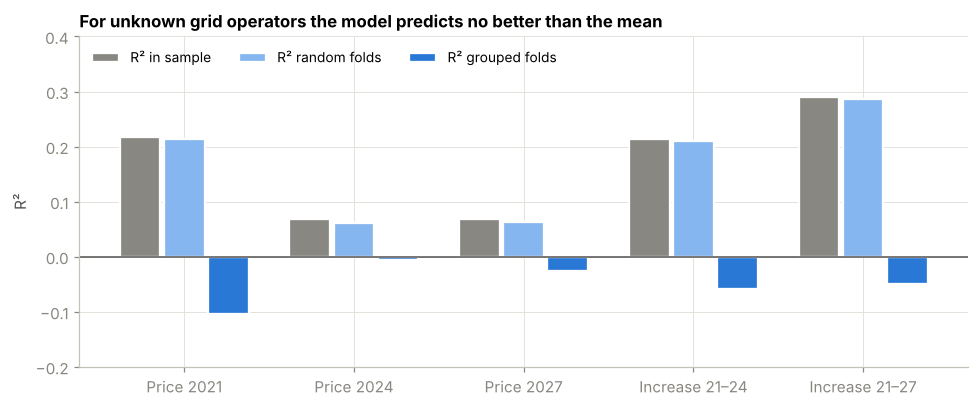

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
spalten = ["R² in sample", "R² random folds", "R² grouped folds"]
farben = ["#898781", "#86b6ef", "#2a78d6"]
x = np.arange(len(cv))
for i, (sp, fa) in enumerate(zip(spalten, farben)):
    ax.bar(x + (i - 1) * 0.26, cv[sp], width=0.24, color=fa, label=sp, edgecolor="white", linewidth=1.5)
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_xticks(x, cv.index)
ax.set_ylabel("R²")
ax.set_title("For unknown grid operators the model predicts no better than the mean", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper left", fontsize=9)
ax.set_ylim(-0.2, 0.4)
fig.tight_layout()

#### Interpretation

With random folds, R² is almost as high as in sample (for example 0.286 compared with 0.290 for the increase from 2021 to 2027). The model is therefore not overfitted.

With folds grouped by grid operator, R² is negative in all five models, between −0.10 and −0.01. For municipalities of an operator the model does not know, the prediction from the municipal characteristics is worse than simply the mean. For the 2021 price, the RMSE is 3.41 cts. compared with 3.24 cts. for the mean.

The difference between the two methods shows where the explanatory power comes from: with random folds, the model already knows an operator's price from its other municipalities. R² in sample therefore mainly measures how well the operators in the data can be told apart, not how well municipal characteristics determine an electricity price.

For the research question this means: the characteristics are suitable for describing relationships and comparing their change over time. They are not suitable for predicting the electricity price of a municipality. That would require knowing the grid operator and its procurement, and the data do not contain this information.

## 7 · Residuals

Checked on the model for the increase from 2021 to 2027, the model with the highest R².

Skewness 0.15, kurtosis 0.53
Share of residual variance between grid operators: 90.4%


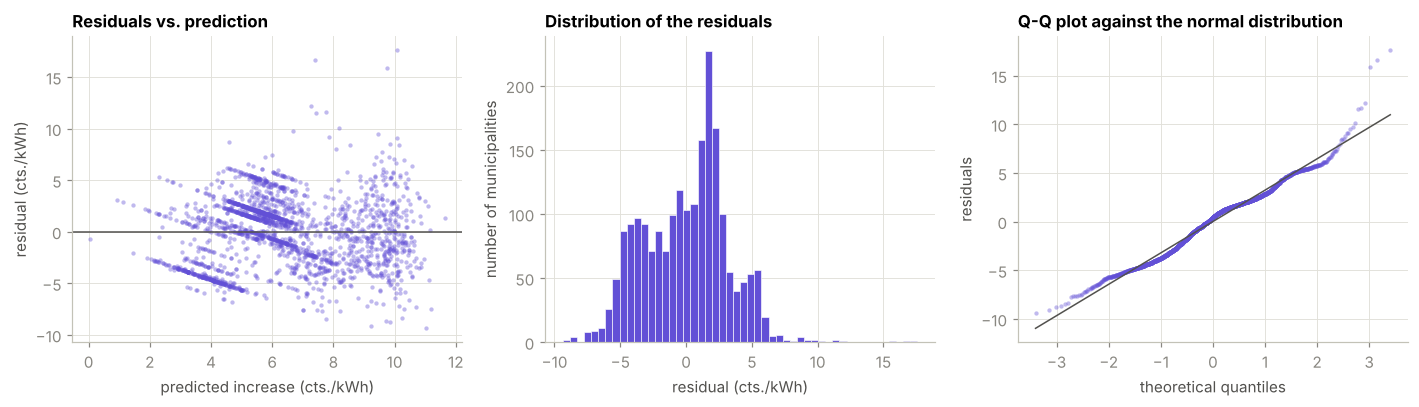

In [14]:
m = modelle_A["anstieg_21_27"]
fig, achsen = plt.subplots(1, 3, figsize=(13, 3.8))
achsen[0].scatter(m["vorhersage"], m["resid"], s=8, alpha=0.4, color="#6250d6", linewidths=0)
achsen[0].axhline(0, color="#52514e", linewidth=1)
achsen[0].set_xlabel("predicted increase (cts./kWh)"); achsen[0].set_ylabel("residual (cts./kWh)")
achsen[0].set_title("Residuals vs. prediction", loc="left")

achsen[1].hist(m["resid"], bins=50, color="#6250d6", edgecolor="white", linewidth=0.4)
achsen[1].set_xlabel("residual (cts./kWh)"); achsen[1].set_ylabel("number of municipalities")
achsen[1].set_title("Distribution of the residuals", loc="left")

(osm, osr), (steigung, achse, _) = stats.probplot(m["resid"], dist="norm")
achsen[2].scatter(osm, osr, s=8, alpha=0.4, color="#6250d6", linewidths=0)
achsen[2].plot(osm, steigung * osm + achse, color="#52514e", linewidth=1)
achsen[2].set_xlabel("theoretical quantiles"); achsen[2].set_ylabel("residuals")
achsen[2].set_title("Q-Q plot against the normal distribution", loc="left")
fig.tight_layout()

resid = pd.Series(m["resid"])
print(f"Skewness {resid.skew():.2f}, kurtosis {resid.kurt():.2f}")
print(f"Share of residual variance between grid operators: "
      f"{resid.groupby(df['netzbetreiber_id'].to_numpy()).transform('mean').var() / resid.var():.1%}")

#### Interpretation

The residuals are roughly symmetric (skewness 0.15) and only slightly heavier-tailed than a normal distribution (kurtosis 0.53). In the Q-Q plot only the largest positive residuals deviate: some municipalities with a much stronger increase than predicted. A funnel pattern in the left diagram, i.e. dispersion growing with the prediction, is not visible.

The diagonal lines in the left diagram stand out. Each line is a grid operator: its municipalities all have the same increase, but different characteristics and therefore different predictions. Hence the slope of −1. The multimodal distribution of the residuals also comes from the large operators.

90 percent of the residual variance lies between the grid operators. The residuals are therefore strongly dependent, which makes the standard errors clustered by operator necessary. Ordinary standard errors would have clearly underestimated the uncertainty.

## 8 · k-means: municipality types

The regression asks how individual characteristics are related to the price. k-means asks a different question: are there groups of municipalities that are similar in their characteristics, and were these groups affected differently by the increase?

Clustering uses only the municipal characteristics, not the prices. Otherwise the comparison of prices between the clusters would be circular.

### 8.1 Characteristics and scaling
Density (log), area (log) and share aged 65+ are used, i.e. the properties of the municipality itself. Operator size stays out because it is not a property of the municipality. k-means measures distances, so all three characteristics are standardised; otherwise the characteristic with the largest range would determine the clusters.

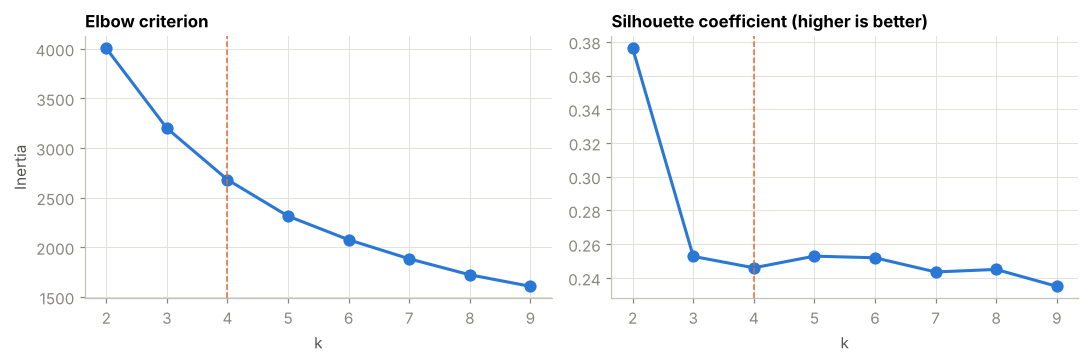

,Inertia,Silhouette
k,,
2,4004.379,0.376
3,3199.220,0.253
4,2681.056,0.246
5,2313.754,0.253
6,2075.539,0.252
7,1883.708,0.244
8,1722.582,0.245
9,1606.464,0.235


In [15]:
CLUSTER_MERKMALE = ["log_dichte", "log_flaeche", "anteil_65plus"]
Z = StandardScaler().fit_transform(df[CLUSTER_MERKMALE])

auswahl = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)
    auswahl.append({"k": k, "Inertia": km.inertia_, "Silhouette": silhouette_score(Z, km.labels_)})
auswahl = pd.DataFrame(auswahl).set_index("k")

fig, achsen = plt.subplots(1, 2, figsize=(10, 3.4))
achsen[0].plot(auswahl.index, auswahl["Inertia"], marker="o", color="#2a78d6", linewidth=2, ms=7)
achsen[0].set_title("Elbow criterion", loc="left"); achsen[0].set_xlabel("k"); achsen[0].set_ylabel("Inertia")
achsen[1].plot(auswahl.index, auswahl["Silhouette"], marker="o", color="#2a78d6", linewidth=2, ms=7)
achsen[1].set_title("Silhouette coefficient (higher is better)", loc="left"); achsen[1].set_xlabel("k")
for ax in achsen:
    ax.axvline(4, color="#eb6834", linewidth=1, linestyle="--")
fig.tight_layout()
auswahl.round(3)

### 8.2 Choice of k

The elbow criterion shows no clear bend. The silhouette coefficient is highest at k = 2, but two clusters only roughly separate town and country. From k = 3 to k = 6 the silhouette is almost the same (differences below 0.01). The data therefore do not force a particular number; the choice is one of content.

**k = 4** is chosen, because the four clusters give clearly distinguishable municipality types that can be named (section 8.3), and all clusters are large enough (over 200 municipalities). A silhouette value of about 0.25 means that the clusters have a recognisable but not a sharp structure: the municipality types merge into one another.

In [16]:
km = KMeans(n_clusters=4, n_init=20, random_state=42).fit(Z)
df["cluster_roh"] = km.labels_

profil = df.groupby("cluster_roh").agg(
    Municipalities=("gemeinde_nr", "size"), Density_median=("dichte", "median"),
    Area_median=("flaeche_total", "median"), Share_65plus=("anteil_65plus", "mean"),
    Population_median=("einwohner", "median"))

# Naming by profile (independent of the random numbering by k-means)
namen = {}
namen[profil["Density_median"].idxmax()] = "Urban, dense"
namen[profil["Area_median"].idxmax()] = "Rural-alpine, large and older"
rest = [c for c in profil.index if c not in namen]
namen[min(rest, key=lambda c: profil.loc[c, "Share_65plus"])] = "Agglomeration, young"
namen[[c for c in rest if c not in namen][0]] = "Rural, medium"
assert len(set(namen.values())) == 4, "Cluster naming is not unique"
REIHENFOLGE = ["Urban, dense", "Agglomeration, young", "Rural, medium", "Rural-alpine, large and older"]
df["gemeindetyp_km"] = pd.Categorical(df["cluster_roh"].map(namen), REIHENFOLGE, ordered=True)
TYP_FARBE = dict(zip(REIHENFOLGE, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

profil.index = profil.index.map(namen)
profil.reindex(REIHENFOLGE).round(1)

,Municipalities,Density_median,Area_median,Share_65plus,Population_median
cluster_roh,,,,,
"Urban, dense",563,626.2,4.7,21.5,2914.0
"Agglomeration, young",627,254.5,5.4,15.3,1298.0
"Rural, medium",666,109.8,16.2,19.1,1756.5
"Rural-alpine, large and older",231,19.2,53.5,26.0,838.0


### 8.3 Profile of the clusters

The naming follows the profile: dense centres with a small area; young agglomeration municipalities of medium density; rural municipalities of medium size; sparsely populated municipalities with a large area and the highest share of older people.

As a check, a comparison with the official municipality typology (German: «Gemeindetypologie») of the Federal Statistical Office (FSO) (2012, 9 types), which k-means did not know. The codes: 11 to 13 urban, 21 to 23 peri-urban, 31 to 33 rural.

In [17]:
pd.crosstab(df["gemeindetyp_km"], df["gemeindetyp_9"].astype("Int64"), margins=True, margins_name="Total")

gemeindetyp_9,11,12,13,21,22,23,31,32,33,Total
gemeindetyp_km,,,,,,,,,,
"Urban, dense",99,126,49,48,93,70,10,63,5,563
"Agglomeration, young",52,29,25,33,158,187,9,126,7,626
"Rural, medium",9,33,43,23,100,158,41,177,82,666
"Rural-alpine, large and older",0,0,3,0,9,34,23,8,154,231
Total,160,188,120,104,360,449,83,374,248,2086


A chi-squared test of independence on this cross table checks whether the clusters and the FSO types are actually related. The null hypothesis: cluster and FSO type are independent. The strength of the relationship is measured by Cramér's V (0 = no relationship, 1 = each cluster corresponds to exactly one type). The test requires that the expected frequencies are below 5 in at most 20 percent of the cells and below 1 in none.

In [18]:
tabelle = pd.crosstab(df["gemeindetyp_km"], df["gemeindetyp_9"].astype("Int64"))
chi2, p_chi2, freiheitsgrade, erwartet = stats.chi2_contingency(tabelle)
n_tab = tabelle.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n_tab * (min(tabelle.shape) - 1)))

print(f"Municipalities in the table: {n_tab} (one municipality without FSO type drops out)")
print(f"Chi² = {chi2:.1f}, degrees of freedom = {freiheitsgrade}, p = {p_chi2:.2g}")
print(f"Cramér's V = {cramers_v:.3f}")
print(f"Requirement: smallest expected frequency {erwartet.min():.1f}, "
      f"cells with expected frequency below 5: {(erwartet < 5).sum()} of {erwartet.size}\n")

# Standardised residuals: which combinations occur much more (+) or less (−) often than under independence
residuen = (tabelle - erwartet) / np.sqrt(erwartet)
residuen.round(1)

Municipalities in the table: 2086 (one municipality without FSO type drops out)
Chi² = 1247.5, degrees of freedom = 24, p = 1.8e-248
Cramér's V = 0.446
Requirement: smallest expected frequency 9.2, cells with expected frequency below 5: 0 of 36



gemeindetyp_9,11,12,13,21,22,23,31,32,33
gemeindetyp_km,,,,,,,,,
"Urban, dense",8.5,10.6,2.9,3.8,-0.4,-4.6,-2.6,-3.8,-7.6
"Agglomeration, young",0.6,-3.7,-1.8,0.3,4.8,4.5,-3.2,1.3,-7.8
"Rural, medium",-5.9,-3.5,0.8,-1.8,-1.4,1.2,2.8,5.3,0.3
"Rural-alpine, large and older",-4.2,-4.6,-2.8,-3.4,-4.9,-2.2,4.6,-5.2,24.1


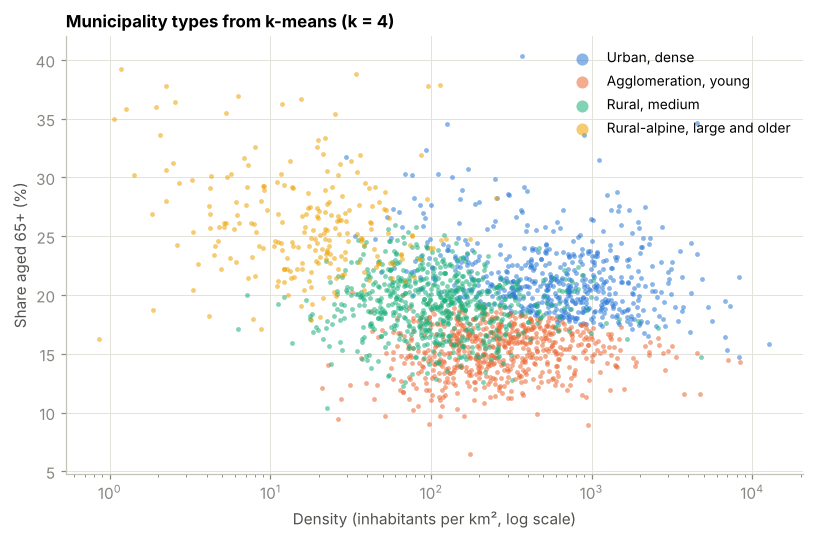

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for typ in REIHENFOLGE:
    t = df[df["gemeindetyp_km"] == typ]
    ax.scatter(t["dichte"], t["anteil_65plus"], s=10, alpha=0.55, color=TYP_FARBE[typ], label=typ, linewidths=0)
ax.set_xscale("log")
ax.set_xlabel("Density (inhabitants per km², log scale)")
ax.set_ylabel("Share aged 65+ (%)")
ax.set_title("Municipality types from k-means (k = 4)", loc="left")
ax.legend(frameon=False, markerscale=2.5, fontsize=9, loc="upper right")
fig.tight_layout()

### 8.4 Were the municipality types affected differently?

ANOVA across the four clusters for each target variable. As in notebook 03, the ANOVA at municipality level is too optimistic, because the municipalities of one operator are not independent. Therefore also a cluster-robust Wald test: a regression of the target variable on the cluster dummies with standard errors clustered by grid operator, testing whether all differences between the clusters are zero.

In [20]:
mittel_typ = df.groupby("gemeindetyp_km", observed=True)[list(ZIELE)].mean().rename(columns=ZIELE)
typ_dummies = pd.get_dummies(df["gemeindetyp_km"], drop_first=True).astype(float)

tests = []
for ziel, name in ZIELE.items():
    gruppen = [g[ziel].to_numpy() for _, g in df.groupby("gemeindetyp_km", observed=True)]
    f = stats.f_oneway(*gruppen)
    gesamt = ((df[ziel] - df[ziel].mean()) ** 2).sum()
    zwischen = sum(len(g) * (g.mean() - df[ziel].mean()) ** 2 for g in gruppen)
    modell = ols_geclustert(df[ziel], typ_dummies, df["netzbetreiber_id"])
    F_w, p_w = wald_test(modell, [1, 2, 3])
    tests.append({"Variable": name, "F (ANOVA)": f.statistic, "p (ANOVA)": f.pvalue,
                  "eta²": zwischen / gesamt, "F (Wald, clustered)": F_w, "p (Wald, clustered)": p_w})
print(mittel_typ.round(2), "\n")
pd.DataFrame(tests).set_index("Variable").round(4)

                               Price 2021  Price 2024  Price 2027  Increase 21–24  Increase 21–27
gemeindetyp_km                                                                                   
Urban, dense                        21.01       32.33       27.29           11.33            6.29
Agglomeration, young                20.12       32.44       27.27           12.32            7.15
Rural, medium                       21.26       31.88       27.48           10.62            6.23
Rural-alpine, large and older       21.38       30.22       26.42            8.84            5.04 



,F (ANOVA),p (ANOVA),eta²,"F (Wald, clustered)","p (Wald, clustered)"
Variable,,,,,
Price 2021,19.8842,0.0000,0.0278,1.6805,0.1703
Price 2024,23.0837,0.0000,0.0322,3.3780,0.0182
Price 2027,7.1498,0.0001,0.0102,1.4909,0.2162
Increase 21–24,41.9425,0.0000,0.0570,7.6143,0.0001
Increase 21–27,18.5868,0.0000,0.0261,4.9679,0.0021


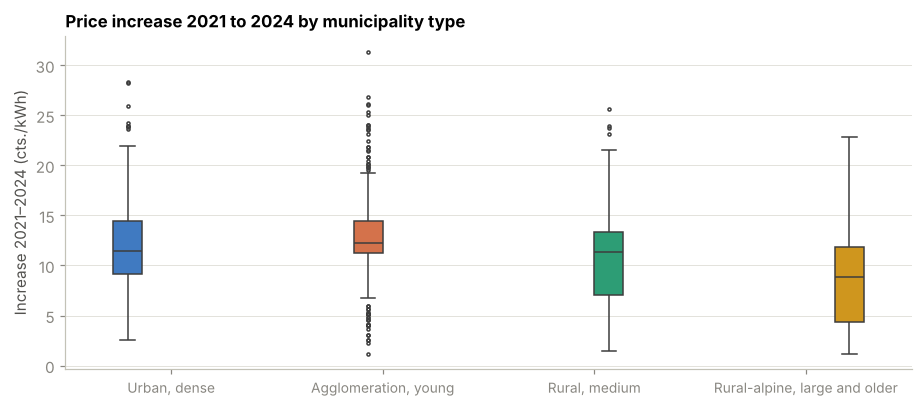

In [21]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sns.boxplot(data=df, x="gemeindetyp_km", y="anstieg_21_24", hue="gemeindetyp_km", palette=TYP_FARBE,
            legend=False, width=0.55, fliersize=2, linewidth=1, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Increase 2021–2024 (cts./kWh)")
ax.set_title("Price increase 2021 to 2024 by municipality type", loc="left")
ax.tick_params(axis="x", labelsize=9)
fig.tight_layout()

#### Interpretation

The four clusters match the official FSO typology well, although k-means did not know it. Of the 231 municipalities in the cluster «Rural-alpine», 154 belong to FSO type 33 (rural peripheral municipality). In the cluster «Urban, dense», 274 of the 563 municipalities are in the urban types 11 to 13. The agglomeration municipalities are spread mainly over the peri-urban types 22 and 23 and the rural central type 32.

The chi-squared test confirms the relationship: Chi² = 1247.5 with 24 degrees of freedom, p < 0.001. Cramér's V is 0.45, which counts as a strong relationship for a table of this size, but is far from a one-to-one assignment. The requirement is met; the smallest expected frequency is 9.2. The standardised residuals show where the agreement lies: it is strongest between «Rural-alpine» and type 33 (+24.1), followed by «Urban, dense» and types 11 and 12 (+8.5 and +10.6). The clusters therefore reflect a spatial pattern that the official typology also knows.

The types differ clearly in the price increase. From 2021 to 2024 the price in the rural-alpine municipalities rose by 8.8 cts. on average, in the young agglomeration municipalities by 12.3 cts. In 2027, too, the rural-alpine municipalities are the cheapest at 26.4 cts.; the others lie between 27.3 and 27.5 cts.

The ordinary ANOVA is highly significant for all five variables, but explains only 1 to 6 percent of the dispersion. The cluster-robust Wald test separates more sharply: the differences are significant for the increase from 2021 to 2024 (p = 0.0001), for the increase from 2021 to 2027 (p = 0.002) and for the 2024 price (p = 0.018). For the 2021 price (p = 0.17) and the 2027 price (p = 0.22) they are not.

The municipality types therefore do not differ in the price level before or after the crisis, but in how hard the crisis hit them. This confirms with a second method what model A shows: the relationships between municipal characteristics and price do not hold equally in all three years.

## 9 · Conclusion

### Answer to the research question

Which characteristics explain the level of the electricity price? Municipal characteristics explain little: 7 to 29 percent of the differences at municipality level, and nothing for municipalities of unknown grid operators. The electricity price of a municipality depends above all on who supplies it. The most stable relationship is with the size of the grid operator: municipalities of the large operators had a smaller increase. This finding, however, rests on a few very large operators and does not hold for operators in general.

Did the relationships change? Yes. Before the crisis, municipalities with many older people were more expensive, and density played no role. At the peak in 2024, dense municipalities were more expensive, and age no longer played a role. Both changes are significant at municipality level. At operator level the change for age holds, the one for density narrowly misses significance (p = 0.059). The rural-alpine municipalities were hit least by the increase. In 2027 the characteristics hardly explain anything any more.

### Coverage of the requirements

| Requirement | Where |
|---|---|
| Mandatory requirement 5: regression with comparison over time periods | Section 3, formal test of the change via the increase models |
| Mandatory requirement 6: quality measures | R², adjusted R² and RMSE in section 3, cross-validation in section 6 |
| Mandatory requirement 7: interpretation | Interpretations in sections 3 to 8 |
| Bonus point 4: test with p-value | ANOVA in section 8.4 and chi-squared test in section 8.3, in addition to notebook 03 |
| Bonus point 5: k-means in addition to the model | Section 8 |

### Limitations

- The municipal characteristics come from 2016 to 2019, the prices from 2021 to 2027.
- The assignment of grid operators is based on the tariff year 2027. Mergers of operators between 2021 and 2027 are not taken into account.
- How the operators procure their electricity (own generation, long-term contracts, market purchases) is not in the data. This is probably what explains the differences in 2024 most.
- All results are associations, not causes.